In [ ]:
Name :-- Rijul Samaiya
Class :-- CSE(Aiml)
Batch :-- A1
Prn :-- 202401110066
Subject :-- Generative Ai
Topic :-- 

In [1]:
import tensorflow as tf, matplotlib, scipy
print(tf.__version__)
print(tf.config.list_physical_devices())

2.21.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [16]:
""" Fashion-MNIST has 60,000 grayscale 28×28 clothing images. A subset of ___ images is used because training runs on a CPU. Pixels are scaled to [-1, 1] to match the generator's tanh output """

" Fashion-MNIST has 60,000 grayscale 28×28 clothing images. A subset of ___ images is used because training runs on a CPU. Pixels are scaled to [-1, 1] to match the generator's tanh output "

In [2]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# ---- hyper-parameters ----
LATENT_DIM = 100
BATCH_SIZE = 128
EPOCHS     = 1        # <-- start with 1 to time it, then change to 10-30
SUBSET     = 20000    # <-- number of training images (max 60000). Use 60000 if your CPU is fast enough
LR         = 2e-4
BETA_1     = 0.5
SAVE_EVERY = 5
OUT_DIR    = "dcgan_fashion_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())

TensorFlow: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [3]:
(train_x, _), (_, _) = keras.datasets.fashion_mnist.load_data()
print("Raw shape:", train_x.shape, "| range:", train_x.min(), "to", train_x.max())

train_x = np.expand_dims(train_x, -1).astype("float32")     # (N, 28, 28) -> (N, 28, 28, 1)
train_x = (train_x - 127.5) / 127.5                         # -> [-1, 1]
train_x = train_x[:SUBSET]
print("Final shape:", train_x.shape, "| range:", train_x.min(), "to", train_x.max())

dataset = (tf.data.Dataset.from_tensor_slices(train_x)
           .shuffle(10000, seed=SEED)
           .batch(BATCH_SIZE, drop_remainder=True)
           .prefetch(tf.data.AUTOTUNE))
steps_per_epoch = len(train_x) // BATCH_SIZE
print("Steps per epoch:", steps_per_epoch)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Raw shape: (60000, 28, 28) | range: 0 to 255
Final shape: (20000, 28, 28, 1) | range: -1.0 to 1.0
Steps per epoch: 156


In [ ]:
""" The generator turns a 100-dimensional noise vector into a 28×28 image using transposed convolutions, batch normalisation and LeakyReLU. """

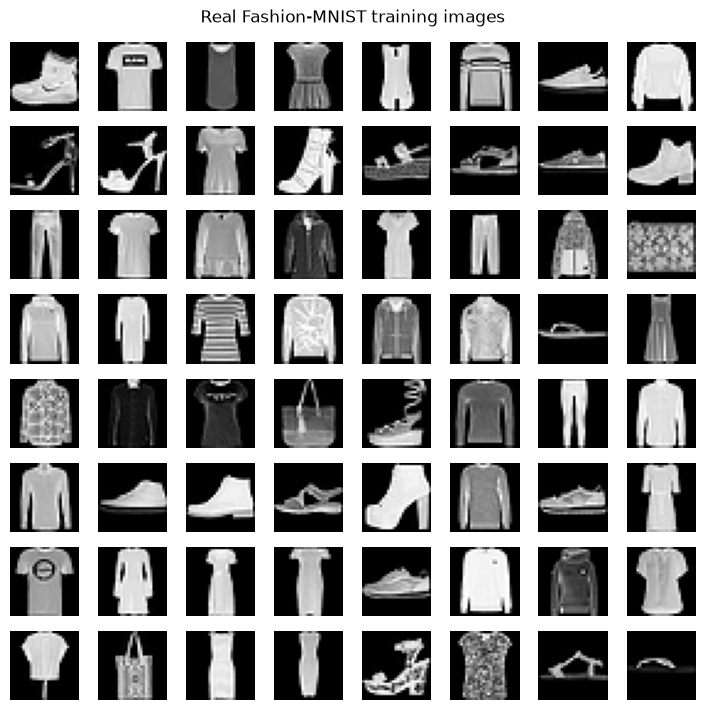

In [4]:
def show_grid(images, n=8, title=None, save_path=None):
    """Plot an n x n grid of grayscale images given in [-1, 1]."""
    images = np.clip((np.asarray(images) + 1.0) / 2.0, 0, 1)
    plt.figure(figsize=(n * 0.9, n * 0.9))
    for i in range(n * n):
        plt.subplot(n, n, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.axis("off")
    if title:
        plt.suptitle(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()

show_grid(train_x[:64], title="Real Fashion-MNIST training images")

In [ ]:
""" The discriminator is a CNN with strided convolutions that outputs one logit, real or fake."""

In [5]:
def build_generator(latent_dim=LATENT_DIM):
    return keras.Sequential([
        keras.Input(shape=(latent_dim,)),
        layers.Dense(7 * 7 * 256, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Reshape((7, 7, 256)),

        layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False),  # 14x14
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),

        layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),   # 28x28
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),

        layers.Conv2D(1, 3, padding="same", activation="tanh"),                     # 1 channel in [-1, 1]
    ], name="generator")

generator = build_generator()
generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 1)      │           577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,961,281 (7.48 MB)

 Trainable params: 1,935,809 (7.38 MB)

 Non-trainable params: 25,472 (99.50 KB)

In [ ]:
""" Discriminator loss is BCE on real (label smoothed to 0.9) plus BCE on fake. Generator loss is BCE with fakes labelled as real. Adam is used with lr 0.0002 and beta1 0.5."""

In [6]:
def build_discriminator():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 4, strides=2, padding="same"),    # 14x14
        layers.LeakyReLU(0.2),

        layers.Conv2D(128, 4, strides=2, padding="same"),   # 7x7
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),

        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(1),                                    # logit
    ], name="discriminator")

discriminator = build_discriminator()
discriminator.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 139,073 (543.25 KB)

 Trainable params: 138,817 (542.25 KB)

 Non-trainable params: 256 (1.00 KB)

In [ ]:
""" At equilibrium the discriminator loss is about 1.39 and the generator loss about 0.69."""

In [10]:
bce   = keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = keras.optimizers.Adam(learning_rate=LR, beta_1=BETA_1)
d_opt = keras.optimizers.Adam(learning_rate=LR, beta_1=BETA_1)

@tf.function
def train_step(real_images):
    batch = tf.shape(real_images)[0]
    noise = tf.random.normal([batch, LATENT_DIM])

    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)

        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(fake_images, training=True)

        # discriminator: real -> 0.9 (smoothed), fake -> 0
        d_loss = (bce(tf.ones_like(real_logits) * 0.9, real_logits)
                  + bce(tf.zeros_like(fake_logits), fake_logits))
        # generator: wants D to output 1 for fakes
        g_loss = bce(tf.ones_like(fake_logits), fake_logits)

    d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    d_opt.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    g_opt.apply_gradients(zip(g_grads, generator.trainable_variables))

    d_real_acc = tf.reduce_mean(tf.cast(real_logits > 0, tf.float32))
    d_fake_acc = tf.reduce_mean(tf.cast(fake_logits < 0, tf.float32))
    return d_loss, g_loss, d_real_acc, d_fake_acc
    

Epoch   1/1 | D loss 1.092 | G loss 1.276 | D acc real 0.65 fake 0.85 | 127s elapsed


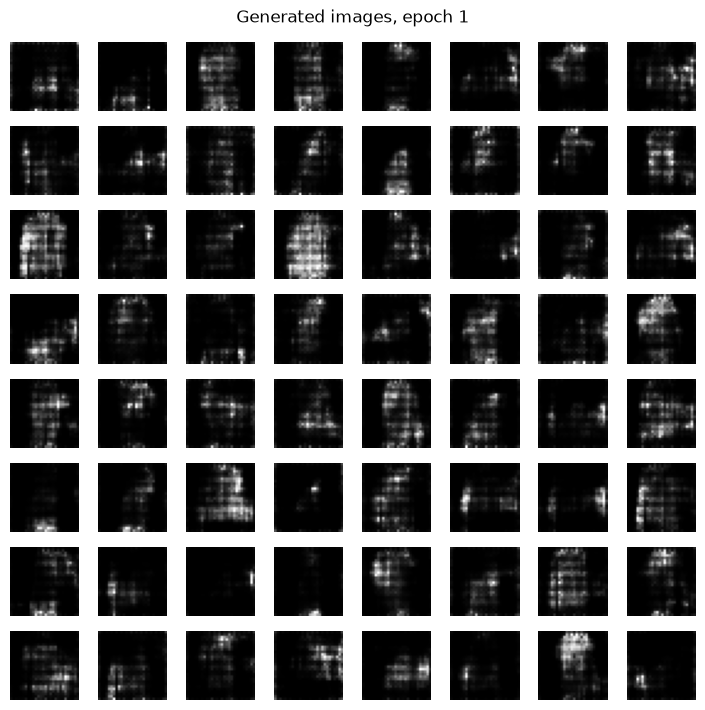

Training finished in 2.1 minutes


In [11]:
fixed_noise = tf.random.normal([64, LATENT_DIM], seed=SEED)

history = {"d_loss": [], "g_loss": [], "d_real_acc": [], "d_fake_acc": []}   # per epoch
step_d, step_g = [], []                                                      # per step

start = time.time()
for epoch in range(1, EPOCHS + 1):
    ep = []
    for batch in dataset:
        d_l, g_l, d_ra, d_fa = train_step(batch)
        ep.append([d_l, g_l, d_ra, d_fa])
    ep = np.array([[float(v) for v in row] for row in ep])
    step_d.extend(ep[:, 0]); step_g.extend(ep[:, 1])
    for k, name in enumerate(history):
        history[name].append(ep[:, k].mean())

    print(f"Epoch {epoch:3d}/{EPOCHS} | D loss {history['d_loss'][-1]:.3f} | "
          f"G loss {history['g_loss'][-1]:.3f} | D acc real {history['d_real_acc'][-1]:.2f} "
          f"fake {history['d_fake_acc'][-1]:.2f} | {time.time() - start:.0f}s elapsed")

    if epoch == 1 or epoch % SAVE_EVERY == 0 or epoch == EPOCHS:
        samples = generator(fixed_noise, training=False).numpy()
        show_grid(samples, title=f"Generated images, epoch {epoch}",
                  save_path=f"{OUT_DIR}/samples_epoch_{epoch:03d}.png")

generator.save(f"{OUT_DIR}/generator.keras")
discriminator.save(f"{OUT_DIR}/discriminator.keras")
print("Training finished in %.1f minutes" % ((time.time() - start) / 60))

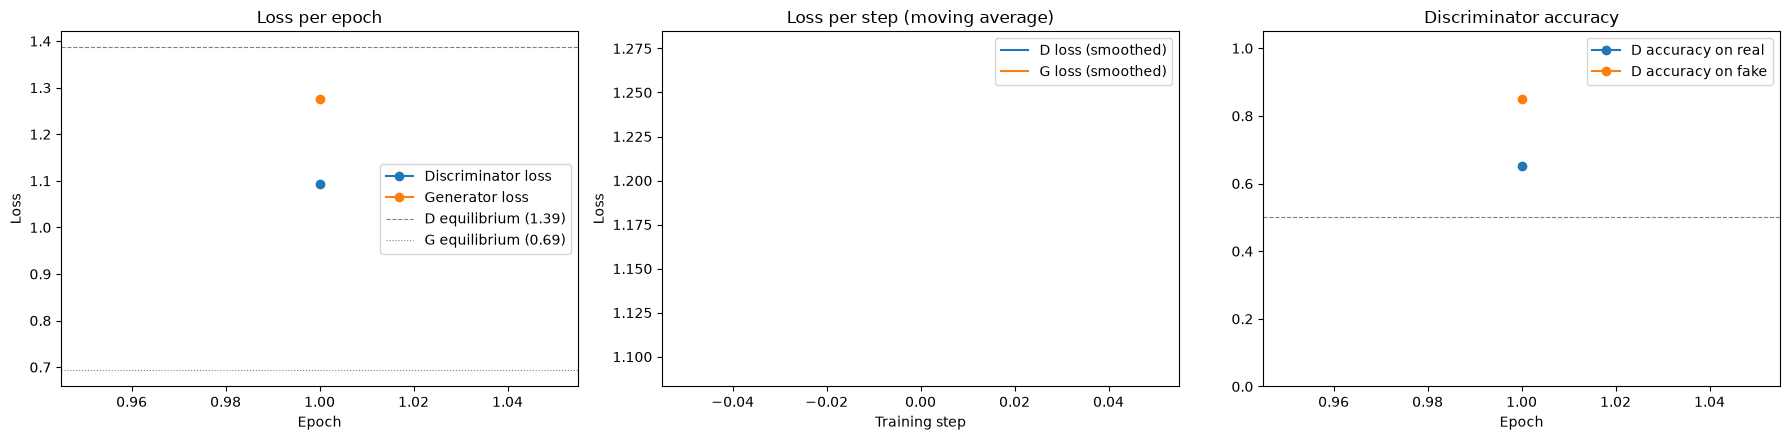

In [12]:
def moving_avg(x, w=200):
    x = np.asarray(x)
    w = min(w, len(x))                      # safe when there are few steps
    return np.convolve(x, np.ones(w) / w, mode="valid")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

# (a) per-epoch losses
ep_axis = range(1, len(history["d_loss"]) + 1)
ax[0].plot(ep_axis, history["d_loss"], marker="o", label="Discriminator loss")
ax[0].plot(ep_axis, history["g_loss"], marker="o", label="Generator loss")
ax[0].axhline(2 * np.log(2), ls="--", c="gray", lw=0.8, label="D equilibrium (1.39)")
ax[0].axhline(np.log(2), ls=":", c="gray", lw=0.8, label="G equilibrium (0.69)")
ax[0].set(title="Loss per epoch", xlabel="Epoch", ylabel="Loss"); ax[0].legend()

# (b) smoothed per-step losses
ax[1].plot(moving_avg(step_d), label="D loss (smoothed)")
ax[1].plot(moving_avg(step_g), label="G loss (smoothed)")
ax[1].set(title="Loss per step (moving average)", xlabel="Training step", ylabel="Loss")
ax[1].legend()

# (c) discriminator accuracy
ax[2].plot(ep_axis, history["d_real_acc"], marker="o", label="D accuracy on real")
ax[2].plot(ep_axis, history["d_fake_acc"], marker="o", label="D accuracy on fake")
ax[2].axhline(0.5, ls="--", c="gray", lw=0.8)
ax[2].set(title="Discriminator accuracy", xlabel="Epoch", ylim=(0, 1.05)); ax[2].legend()

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

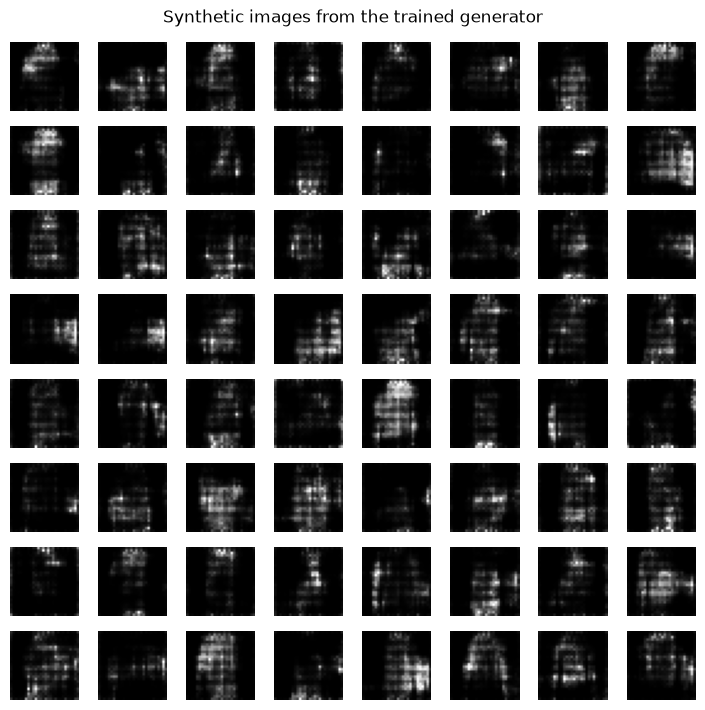

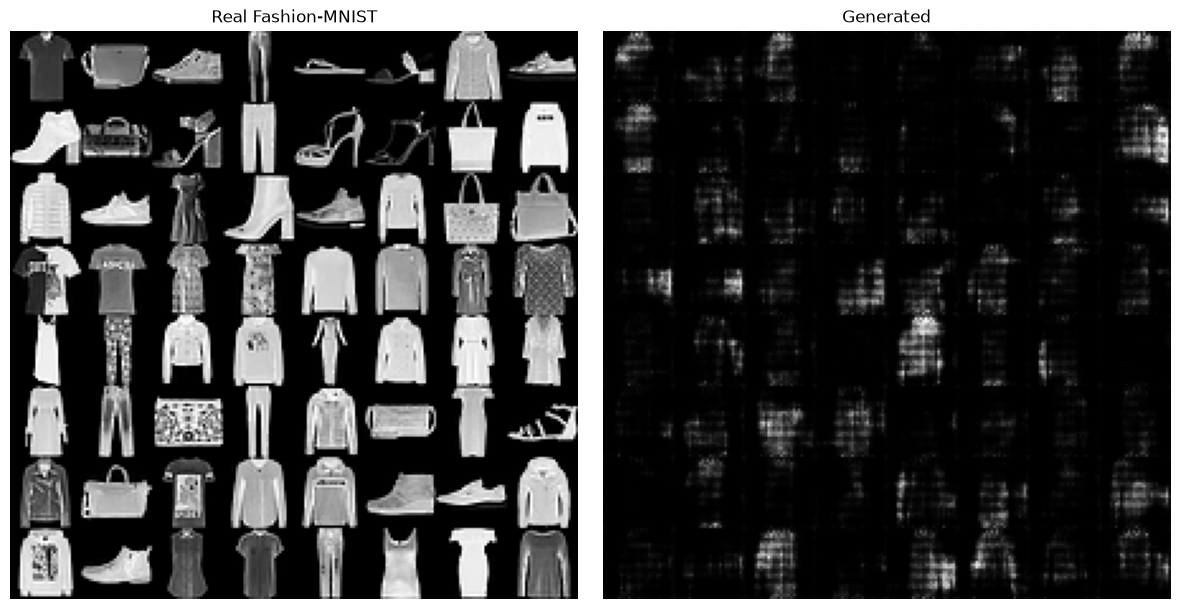

In [13]:
generator = keras.models.load_model(f"{OUT_DIR}/generator.keras")
noise = tf.random.normal([64, LATENT_DIM], seed=123)
fake = generator(noise, training=False).numpy()
show_grid(fake, title="Synthetic images from the trained generator",
          save_path=f"{OUT_DIR}/final_generated.png")

# side by side comparison with real images
idx = np.random.RandomState(0).choice(len(train_x), 64, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, imgs, t in zip(ax, [train_x[idx], fake], ["Real Fashion-MNIST", "Generated"]):
    grid = np.clip((imgs.squeeze() + 1) / 2, 0, 1).reshape(8, 8, 28, 28).transpose(0, 2, 1, 3).reshape(224, 224)
    a.imshow(grid, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/real_vs_generated.png", dpi=150, bbox_inches="tight")
plt.show()

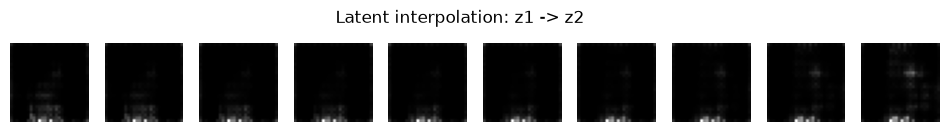

In [14]:
z1 = tf.random.normal([1, LATENT_DIM], seed=1)
z2 = tf.random.normal([1, LATENT_DIM], seed=2)
steps = 10
zs = tf.concat([z1 * (1 - a) + z2 * a for a in np.linspace(0, 1, steps)], axis=0)
imgs = np.clip((generator(zs, training=False).numpy() + 1) / 2, 0, 1)

plt.figure(figsize=(steps * 1.2, 1.5))
for i in range(steps):
    plt.subplot(1, steps, i + 1); plt.imshow(imgs[i].squeeze(), cmap="gray"); plt.axis("off")
plt.suptitle("Latent interpolation: z1 -> z2")
plt.savefig(f"{OUT_DIR}/interpolation.png", dpi=150, bbox_inches="tight")
plt.show()

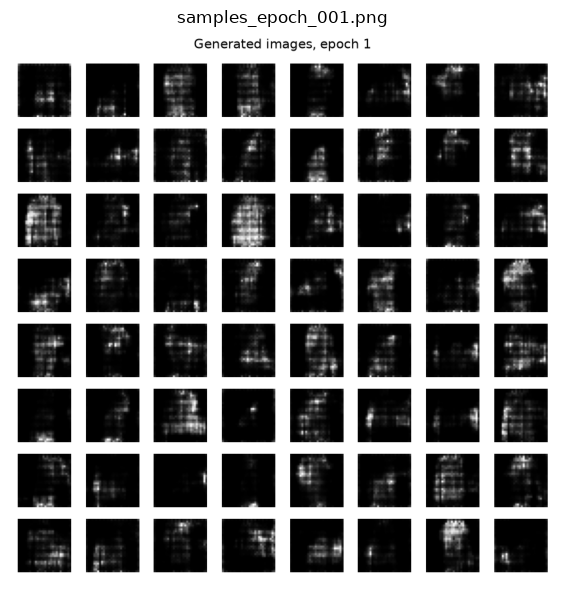

In [15]:
import glob
from matplotlib.image import imread
files = sorted(glob.glob(f"{OUT_DIR}/samples_epoch_*.png"))
pick = [files[0], files[len(files) // 2], files[-1]] if len(files) >= 3 else files
fig, ax = plt.subplots(1, len(pick), figsize=(6 * len(pick), 6))
ax = np.atleast_1d(ax)
for a, f in zip(ax, pick):
    a.imshow(imread(f)); a.axis("off"); a.set_title(os.path.basename(f))
plt.tight_layout(); plt.show()

In [ ]:
""" - Trained for ____ epochs on ____ images. Time per epoch: ____ seconds.
- D loss settled around ____ and G loss around ____ (equilibrium ≈ 1.39 and 0.69).
- Discriminator accuracy at the end: real ____, fake ____.
- Epoch 1 images looked like ____. The final images show ____.
- Diversity: the 64 images look (varied / repetitive).
- Latent interpolation changes (smoothly / abruptly).

## Conclusion
A DCGAN was trained on Fashion-MNIST for ____ epochs. The loss curves showed ____.
The generated images ____. Limitation: training on a CPU with a ____-image subset
and few epochs limits image quality."""